# A/B Testing Portfolio Project: Checkout Conversion

**Business question:** Does a simpler checkout experience increase conversion?

This notebook analyses a **synthetic, Amazon-inspired checkout experiment**. It compares a control checkout with a simplified treatment checkout, tests conversion and revenue-per-session differences, and explores illustrative commercial scenarios.

> **Data disclaimer:** These data are synthetic and do not represent actual Amazon customer data or performance. Commercial scenarios are assumptions, not forecasts.

**Workflow:** SQL data validation → Python statistical analysis → Power BI dashboard.

## 1. Analysis plan

1. Load the supplied synthetic session-level analysis dataset and order table.
2. Check schema, uniqueness, conversion indicators and order-to-session links.
3. Compare conversion rates and calculate the absolute and relative lift.
4. Test the conversion-rate difference using a two-sided two-proportion z-test and estimate an approximate 95% confidence interval.
5. Compare revenue per session using Welch's two-sample t-test.
6. Model illustrative revenue scenarios and export tidy tables for Power BI.

The analysis uses a 5% significance threshold. The statistical tests and commercial scenario model answer different questions: statistical evidence does not, by itself, establish whether an implementation is commercially worthwhile.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

# Find the project root whether Jupyter starts in the repository root or analysis/.
current_dir = Path.cwd().resolve()
possible_roots = [current_dir, current_dir.parent]
PROJECT_ROOT = next(
    (candidate for candidate in possible_roots
     if (candidate / "data" / "checkout_session_analysis.csv").exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/checkout_session_analysis.csv. "
        "Keep the notebook in analysis/ and the supplied CSVs in data/."
    )

DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Output folder: {OUTPUT_DIR}")

Project root: /mnt/data/amazon_ab_testing_upload_pack
Output folder: /mnt/data/amazon_ab_testing_upload_pack/output


## 2. Load the datasets

`checkout_session_analysis.csv` contains one row per assigned session. `checkout_orders.csv` contains the synthetic order-level revenue values used to calculate revenue per session.

In [2]:
sessions = pd.read_csv(DATA_DIR / "checkout_session_analysis.csv")
orders = pd.read_csv(DATA_DIR / "checkout_orders.csv")

print(f"Session-level rows: {len(sessions):,}")
print(f"Order rows: {len(orders):,}")
display(sessions.head())
display(orders.head())

Session-level rows: 12,000
Order rows: 1,274


,session_id,variant,eligible,exposed,converted,conversion_timestamp,synthetic_order_id
0,ABSESS000001,control,1,1,0,NaN,NaN
1,ABSESS000002,control,1,1,0,NaN,NaN
2,ABSESS000003,treatment,1,1,0,NaN,NaN
3,ABSESS000004,control,1,1,0,NaN,NaN
4,ABSESS000005,treatment,1,1,0,NaN,NaN


,synthetic_order_id,session_id,order_timestamp,order_status,currency,order_value_gbp,is_synthetic
0,ABORD9000001,ABSESS000008,2026-08-15 03:35:17,Completed,GBP,42.13,1
1,ABORD9000002,ABSESS000017,2026-08-11 09:48:52,Completed,GBP,189.01,1
2,ABORD9000003,ABSESS000054,2026-08-28 15:47:45,Completed,GBP,245.54,1
3,ABORD9000004,ABSESS000059,2026-08-06 02:36:22,Completed,GBP,64.25,1
4,ABORD9000005,ABSESS000069,2026-08-15 23:06:12,Completed,GBP,32.86,1


## 3. Validate the data before analysing outcomes

The checks below verify the expected fields, session uniqueness, binary indicators, unique order IDs, and consistency between conversion IDs and order/session records. A clean check means only that the specified condition passed; it does not prove that the synthetic data are error-free or representative of a real experiment.

In [3]:
required_session_columns = {
    "session_id", "variant", "eligible", "exposed", "converted", "synthetic_order_id"
}
required_order_columns = {"synthetic_order_id", "session_id", "order_value_gbp"}

missing_session_columns = required_session_columns - set(sessions.columns)
missing_order_columns = required_order_columns - set(orders.columns)
if missing_session_columns:
    raise ValueError(f"Session dataset is missing columns: {sorted(missing_session_columns)}")
if missing_order_columns:
    raise ValueError(f"Order dataset is missing columns: {sorted(missing_order_columns)}")

# Standardise variant labels and make binary fields numeric for validation.
sessions["variant"] = sessions["variant"].astype("string").str.strip().str.lower()
for column in ["eligible", "exposed", "converted"]:
    sessions[column] = pd.to_numeric(sessions[column], errors="coerce")
orders["order_value_gbp"] = pd.to_numeric(orders["order_value_gbp"], errors="coerce")

quality_checks = pd.DataFrame([
    ("Session rows", len(sessions)),
    ("Unique session IDs", sessions["session_id"].nunique(dropna=True)),
    ("Duplicate session IDs", int(sessions["session_id"].duplicated().sum())),
    ("Missing session IDs", int(sessions["session_id"].isna().sum())),
    ("Missing variant labels", int(sessions["variant"].isna().sum())),
    ("Invalid variant labels", int((~sessions["variant"].isin(["control", "treatment"])).sum()),),
    ("Invalid conversion indicators", int((~sessions["converted"].isin([0, 1])).sum())),
    ("Invalid eligibility indicators", int((~sessions["eligible"].isin([0, 1])).sum())),
    ("Invalid exposure indicators", int((~sessions["exposed"].isin([0, 1])).sum())),
    ("Duplicate order IDs", int(orders["synthetic_order_id"].duplicated().sum())),
    ("Missing/non-positive order values", int((orders["order_value_gbp"].isna() | (orders["order_value_gbp"] <= 0)).sum())),
    ("Converted sessions missing order IDs", int(((sessions["converted"] == 1) & sessions["synthetic_order_id"].isna()).sum())),
], columns=["Check", "Result"])

display(quality_checks)

# Validate the assignment mix and high-level sample assumptions.
variant_counts = sessions["variant"].value_counts(dropna=False).rename_axis("variant").reset_index(name="sessions")
display(variant_counts)

assert sessions["session_id"].is_unique, "Expected one row per session."
assert set(sessions["variant"].dropna().unique()) == {"control", "treatment"}, "Unexpected variant labels."
assert sessions["converted"].isin([0, 1]).all(), "Conversion field must be binary and non-missing."
assert sessions["eligible"].isin([0, 1]).all(), "Eligibility field must be binary and non-missing."
assert sessions["exposed"].isin([0, 1]).all(), "Exposure field must be binary and non-missing."
assert orders["synthetic_order_id"].is_unique, "Order IDs must be unique in the order table."

,Check,Result
0,Session rows,12000
1,Unique session IDs,12000
2,Duplicate session IDs,0
3,Missing session IDs,0
4,Missing variant labels,0
5,Invalid variant labels,0
6,Invalid conversion indicators,0
7,Invalid eligibility indicators,0
8,Invalid exposure indicators,0
9,Duplicate order IDs,0


,variant,sessions
0,control,6000
1,treatment,6000


## 4. Check the order-to-session relationship

The merge keeps all sessions, including non-converting sessions. Revenue is set to zero for sessions without an order. The check verifies that each recorded conversion's order ID exists and is linked to the same session.

In [4]:
analysis = sessions.merge(
    orders[["synthetic_order_id", "session_id", "order_value_gbp"]],
    on="synthetic_order_id",
    how="left",
    suffixes=("", "_order"),
    validate="many_to_one",
)

converted_mask = analysis["converted"].eq(1)
missing_order_for_conversion = int(
    (converted_mask & analysis["order_value_gbp"].isna()).sum()
)
order_session_mismatch = int(
    (converted_mask
     & analysis["session_id_order"].notna()
     & analysis["session_id"].ne(analysis["session_id_order"])).sum()
)
order_ids_in_sessions = set(sessions["synthetic_order_id"].dropna())
order_ids_in_orders = set(orders["synthetic_order_id"].dropna())
orders_without_conversion_reference = len(order_ids_in_orders - order_ids_in_sessions)

link_checks = pd.DataFrame([
    ("Converted sessions missing a matching order", missing_order_for_conversion),
    ("Converted sessions linked to another session's order", order_session_mismatch),
    ("Orders not referenced by any session outcome", orders_without_conversion_reference),
], columns=["Check", "Issue count"])
display(link_checks)

assert missing_order_for_conversion == 0, "At least one conversion is missing a matching order."
assert order_session_mismatch == 0, "At least one order is linked to a different session."
assert orders_without_conversion_reference == 0, "At least one order is not referenced by the session outcomes."

analysis["revenue_per_session_gbp"] = analysis["order_value_gbp"].fillna(0.0)
print("Order-to-session link checks passed for the conditions tested.")

,Check,Issue count
0,Converted sessions missing a matching order,0
1,Converted sessions linked to another session's...,0
2,Orders not referenced by any session outcome,0


Order-to-session link checks passed for the conditions tested.


## 5. Conversion-rate analysis

Conversion rate is calculated as converted sessions divided by all assigned sessions in each variant. The primary comparison is treatment minus control.

In [5]:
conversion_results = sessions.groupby("variant", observed=True).agg(
    sessions=("session_id", "nunique"),
    conversions=("converted", "sum"),
)
conversion_results["conversion_rate"] = (
    conversion_results["conversions"] / conversion_results["sessions"]
)
conversion_results["conversion_rate_pct"] = conversion_results["conversion_rate"] * 100
conversion_results = conversion_results.reindex(["control", "treatment"])
display(conversion_results.round(5))

control_sessions = int(conversion_results.loc["control", "sessions"])
treatment_sessions = int(conversion_results.loc["treatment", "sessions"])
control_conversions = int(conversion_results.loc["control", "conversions"])
treatment_conversions = int(conversion_results.loc["treatment", "conversions"])
control_rate = float(conversion_results.loc["control", "conversion_rate"])
treatment_rate = float(conversion_results.loc["treatment", "conversion_rate"])

absolute_difference = treatment_rate - control_rate
absolute_difference_pp = absolute_difference * 100
relative_lift_pct = absolute_difference / control_rate * 100
observed_conversion_count_difference = treatment_conversions - control_conversions

print(f"Absolute difference: {absolute_difference_pp:.3f} percentage points")
print(f"Relative lift: {relative_lift_pct:.2f}%")
print(f"Difference in observed conversions between equal-sized groups: {observed_conversion_count_difference}")

,sessions,conversions,conversion_rate,conversion_rate_pct
variant,,,,
control,6000,605,0.10083,10.08333
treatment,6000,669,0.11150,11.15000


Absolute difference: 1.067 percentage points
Relative lift: 10.58%
Difference in observed conversions between equal-sized groups: 64


In [6]:
# Two-sided two-proportion z-test at alpha = 0.05.
alpha = 0.05
z_statistic, conversion_p_value = proportions_ztest(
    count=np.array([treatment_conversions, control_conversions]),
    nobs=np.array([treatment_sessions, control_sessions]),
    alternative="two-sided",
)

# Approximate unpooled normal 95% confidence interval for treatment minus control.
standard_error_difference = np.sqrt(
    treatment_rate * (1 - treatment_rate) / treatment_sessions
    + control_rate * (1 - control_rate) / control_sessions
)
ci_lower = absolute_difference - stats.norm.ppf(1 - alpha / 2) * standard_error_difference
ci_upper = absolute_difference + stats.norm.ppf(1 - alpha / 2) * standard_error_difference

conversion_test_results = pd.DataFrame([{
    "z_statistic": z_statistic,
    "p_value": conversion_p_value,
    "alpha": alpha,
    "ci_lower_pp": ci_lower * 100,
    "ci_upper_pp": ci_upper * 100,
    "statistically_significant": conversion_p_value < alpha,
}])
display(conversion_test_results.round(5))

print(
    "Conclusion:",
    "statistically significant at the 5% level" if conversion_p_value < alpha
    else "not statistically significant at the 5% level",
)
print(f"Approximate 95% CI for conversion lift: {ci_lower * 100:.3f} to {ci_upper * 100:.3f} percentage points")

,z_statistic,p_value,alpha,ci_lower_pp,ci_upper_pp,statistically_significant
0,1.89656,0.05789,0.05,-0.03549,2.16883,False


Conclusion: not statistically significant at the 5% level
Approximate 95% CI for conversion lift: -0.035 to 2.169 percentage points


## 6. Revenue-per-session analysis

Revenue per session includes **£0 for non-converting sessions**. Welch's two-sample t-test compares mean revenue per session between the variants without assuming equal variances. Revenue per session is not the same as average order value.

In [7]:
revenue_results = analysis.groupby("variant", observed=True).agg(
    sessions=("session_id", "nunique"),
    conversions=("converted", "sum"),
    total_revenue_gbp=("revenue_per_session_gbp", "sum"),
    average_order_value_gbp=("order_value_gbp", "mean"),
)
revenue_results["revenue_per_session_gbp"] = (
    revenue_results["total_revenue_gbp"] / revenue_results["sessions"]
)
revenue_results["conversion_rate_pct"] = (
    revenue_results["conversions"] / revenue_results["sessions"] * 100
)
revenue_results = revenue_results.reindex(["control", "treatment"])
display(revenue_results.round(4))

control_revenue_per_session = analysis.loc[
    analysis["variant"].eq("control"), "revenue_per_session_gbp"
]
treatment_revenue_per_session = analysis.loc[
    analysis["variant"].eq("treatment"), "revenue_per_session_gbp"
]

welch_result = stats.ttest_ind(
    treatment_revenue_per_session,
    control_revenue_per_session,
    equal_var=False,
    alternative="two-sided",
)
revenue_p_value = float(welch_result.pvalue)
revenue_per_session_difference = (
    treatment_revenue_per_session.mean() - control_revenue_per_session.mean()
)

revenue_test_results = pd.DataFrame([{
    "control_revenue_per_session_gbp": control_revenue_per_session.mean(),
    "treatment_revenue_per_session_gbp": treatment_revenue_per_session.mean(),
    "difference_gbp": revenue_per_session_difference,
    "welch_t_statistic": welch_result.statistic,
    "p_value": revenue_p_value,
    "alpha": alpha,
    "statistically_significant": revenue_p_value < alpha,
}])
display(revenue_test_results.round(5))

print(
    "Conclusion:",
    "statistically significant at the 5% level" if revenue_p_value < alpha
    else "not statistically significant at the 5% level",
)

,sessions,conversions,total_revenue_gbp,average_order_value_gbp,revenue_per_session_gbp,conversion_rate_pct
variant,,,,,,
control,6000,605,72509.57,119.8505,12.0849,10.0833
treatment,6000,669,80006.22,119.5908,13.3344,11.1500


,control_revenue_per_session_gbp,treatment_revenue_per_session_gbp,difference_gbp,welch_t_statistic,p_value,alpha,statistically_significant
0,12.08493,13.33437,1.24944,1.61276,0.10682,0.05,False


Conclusion: not statistically significant at the 5% level


## 7. Illustrative commercial scenarios

These scenarios show how gross revenue changes under different assumed conversion-rate changes. They use **100,000 monthly sessions** and the observed mean order value across the synthetic orders. The values are not forecasts.

A scenario that subtracts implementation and maintenance expenses from gross incremental revenue is labelled **gross revenue less fixed costs**—not profit—because product, fulfilment, payment and other variable costs are excluded.

In [8]:
average_order_value_gbp = float(orders["order_value_gbp"].mean())
monthly_sessions = 100_000
implementation_cost_gbp = 15_000
monthly_maintenance_cost_gbp = 1_000
evaluation_months = 12

scenarios = pd.DataFrame({
    "scenario": [
        "Lower confidence bound",
        "No improvement",
        "Small improvement",
        "Observed improvement",
        "Upper confidence bound",
    ],
    # Rounded scenario inputs match the values displayed in the Power BI dashboard.
    # The exact confidence interval is reported in the statistical-test section above.
    "conversion_change_pp": [-0.036, 0.0, 0.5, 1.067, 2.169],
})
scenarios["conversion_change_proportion"] = scenarios["conversion_change_pp"] / 100
scenarios["assumed_monthly_sessions"] = monthly_sessions
scenarios["estimated_extra_conversions_monthly"] = (
    monthly_sessions * scenarios["conversion_change_proportion"]
)
scenarios["incremental_gross_revenue_monthly_gbp"] = (
    scenarios["estimated_extra_conversions_monthly"] * average_order_value_gbp
)
scenarios["gross_revenue_less_fixed_costs_12m_gbp"] = (
    scenarios["incremental_gross_revenue_monthly_gbp"] * evaluation_months
    - implementation_cost_gbp
    - monthly_maintenance_cost_gbp * evaluation_months
)

display(scenarios.round(2))
print(f"Average order value used in scenarios: £{average_order_value_gbp:.2f}")
print("Scenario values are illustrative gross-revenue estimates; they are not profit forecasts.")

,scenario,conversion_change_pp,conversion_change_proportion,assumed_monthly_sessions,estimated_extra_conversions_monthly,incremental_gross_revenue_monthly_gbp,gross_revenue_less_fixed_costs_12m_gbp
0,Lower confidence bound,-0.04,-0.00,100000,-36.0,-4309.71,-78716.50
1,No improvement,0.00,0.00,100000,0.0,0.00,-27000.00
2,Small improvement,0.50,0.00,100000,500.0,59857.06,691284.73
3,Observed improvement,1.07,0.01,100000,1067.0,127734.97,1505819.60
4,Upper confidence bound,2.17,0.02,100000,2169.0,259659.93,3088919.14


Average order value used in scenarios: £119.71
Scenario values are illustrative gross-revenue estimates; they are not profit forecasts.


## 8. Visualise the principal results

The conversion chart shows the observed rates, not statistical certainty. The p-value and confidence interval above should be considered alongside it.

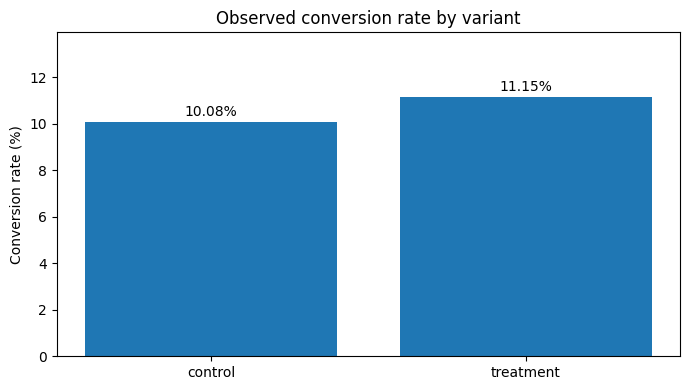

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
plot_rates = conversion_results["conversion_rate_pct"]
ax.bar(plot_rates.index, plot_rates.values)
ax.set_ylabel("Conversion rate (%)")
ax.set_title("Observed conversion rate by variant")
ax.set_ylim(0, max(plot_rates.values) * 1.25)
for x, value in enumerate(plot_rates.values):
    ax.text(x, value + 0.12, f"{value:.2f}%", ha="center", va="bottom")
plt.tight_layout()
plt.show()

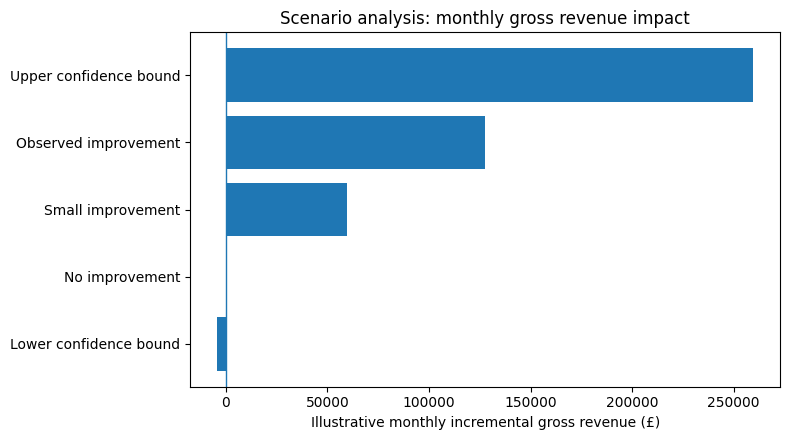

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
scenario_plot = scenarios.set_index("scenario")["incremental_gross_revenue_monthly_gbp"]
ax.barh(scenario_plot.index, scenario_plot.values)
ax.axvline(0, linewidth=1)
ax.set_xlabel("Illustrative monthly incremental gross revenue (£)")
ax.set_title("Scenario analysis: monthly gross revenue impact")
plt.tight_layout()
plt.show()

## 9. Overall findings and recommendation

The treatment group showed a higher observed conversion rate and revenue per session, but **neither difference was statistically significant at the 5% level**. The conversion confidence interval also spans zero, so the true conversion effect remains uncertain.

**Recommendation:** increase the sample beyond 12,000 sessions and retest using a predefined sample-size calculation and decision criteria. Before rollout, assess statistical evidence, commercial value using contribution margin and costs, and customer-experience guardrails.

**Limitations:** the data are synthetic; the sample-size assumptions and scenario inputs are illustrative; and the commercial model estimates gross revenue rather than profit.

## 10. Export tidy tables for Power BI

The exports contain named columns (no dataframe index column) and are saved to the repository's `output/` folder. These CSVs support the dashboard; they do not replace the analysis steps above.

In [11]:
# Conversion table
conversion_export = conversion_results.reset_index()
conversion_export.to_csv(OUTPUT_DIR / "powerbi_conversion_results.csv", index=False)

# Revenue table
revenue_export = revenue_results.reset_index()
revenue_export.to_csv(OUTPUT_DIR / "powerbi_revenue_results.csv", index=False)

# Overall experiment summary
experiment_summary = pd.DataFrame([{
    "control_conversion_pct": control_rate * 100,
    "treatment_conversion_pct": treatment_rate * 100,
    "absolute_difference_pp": absolute_difference_pp,
    "relative_lift_pct": relative_lift_pct,
    "conversion_p_value": conversion_p_value,
    "revenue_p_value": revenue_p_value,
    "conversion_ci_lower_pp": ci_lower * 100,
    "conversion_ci_upper_pp": ci_upper * 100,
    "data_type": "Synthetic",
    "recommendation": "Retest with a predefined sample-size calculation",
}])
experiment_summary.to_csv(OUTPUT_DIR / "powerbi_experiment_summary.csv", index=False)

# Scenario table
scenarios.to_csv(OUTPUT_DIR / "powerbi_business_scenarios.csv", index=False)

print("Exported files:")
for file_path in sorted(OUTPUT_DIR.glob("*.csv")):
    print(f"- {file_path.name} ({file_path.stat().st_size:,} bytes)")

Exported files:
- powerbi_business_scenarios.csv (614 bytes)
- powerbi_conversion_results.csv (153 bytes)
- powerbi_experiment_summary.csv (394 bytes)
- powerbi_revenue_results.csv (260 bytes)
